In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.decomposition import PCA

from cluster_weather_years.functions import build_df, plot_clim_per_cluster

from cluster_weather_years.constants import NUM_CLUSTERS, BASE_OUTPUT

In [2]:
# Build NL dataframe
df_daily, df_nl_rolling = build_df()

# 1. Compute mean and standard deviation per year w.r.t. climatology, just for visualisation

In [3]:
clim_means = df_daily.mean(axis=0)

yearly_means = df_daily.groupby(
    [pd.Grouper(level="model"), df_nl_rolling.index.get_level_values("Date").year]
).agg("mean")

# normalize it by the climatological mean, and convert into percentage
yearly_mean_anom_norm = (yearly_means - clim_means) * 100 / clim_means

clim_stds = df_daily.std(axis=0)
yearly_stds = df_daily.groupby(
    [pd.Grouper(level="model"), df_nl_rolling.index.get_level_values("Date").year]
).agg("std")

# normalize it by the climatological std, and convert into percentage
yearly_std_anom_norm = (yearly_stds - clim_stds) * 100 / clim_stds

(-50.0, 50.0)

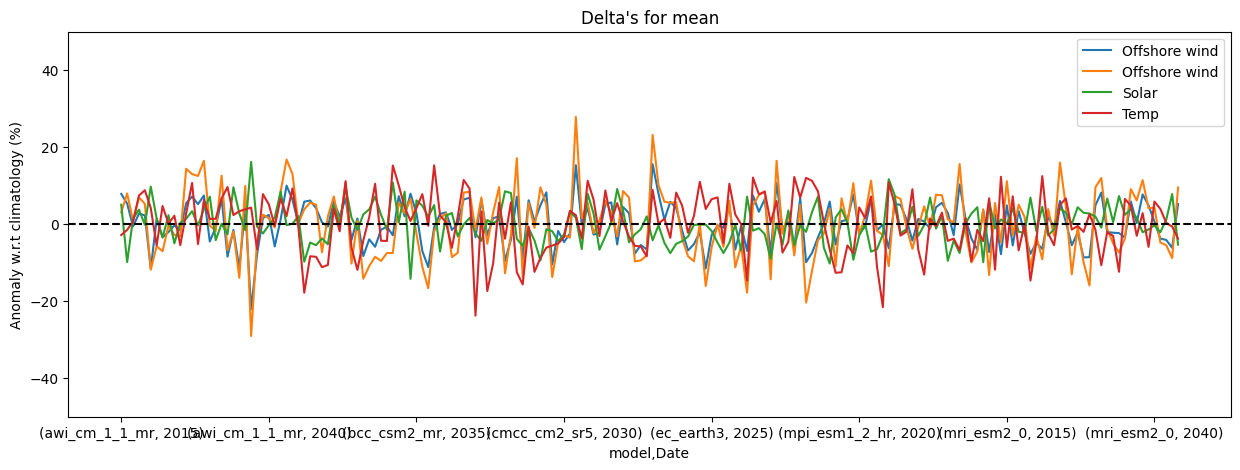

In [4]:
# NOTE: CDD is out of bounds for these plotting ylims.
plt.figure(figsize=(15, 5))
yearly_mean_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_mean_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")
# yearly_mean_anom_norm["CDD"].plot(label="CDD")
# yearly_mean_anom_norm["HDD"].plot(label="HDD")

plt.legend()
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for mean")
plt.ylim(-50, 50)

(-50.0, 50.0)

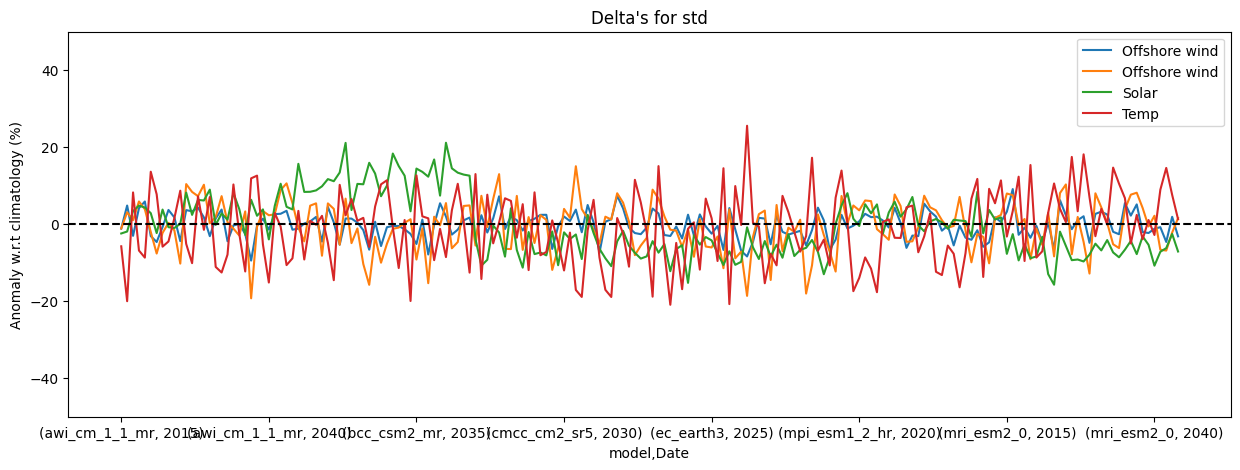

In [5]:
plt.figure(figsize=(15, 5))

yearly_std_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_std_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")

# yearly_std_anom_norm["CDD"].plot(label="CDD")
# yearly_std_anom_norm["HDD"].plot(label="HDD")


plt.legend(loc="upper right")
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for std")
plt.ylim(-50, 50)

# 2. Perform K-Medoids clustering

In [6]:
# standardize the data to mean = 0, std = 1
# TODO: Add HDD and CDD instead of TEMP
df_standardize = df_daily[["NL_OFF", "NL_ON", "NL_SOLAR", "NL_TEMP"]]

scaler = StandardScaler()
df_standardized = pd.DataFrame(
    scaler.fit_transform(df_standardize),
    columns=df_standardize.columns,
    index=df_daily.index,
)

In [7]:
def p95_day(s: pd.Series) -> float:
    """Return the 95th percentile of a Series."""
    return s.quantile(0.95)


def p5_day(s: pd.Series) -> float:
    """Return the 5th percentile of a Series."""
    return s.quantile(0.05)


def p95_week(s: pd.Series) -> float:
    """Return the 95th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.95)


def p5_week(s: pd.Series) -> float:
    """Return the 5th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.05)


year = pd.Index(
    df_nl_rolling.index.get_level_values("Date").year,
    name="year",
)

yearly_stats = df_standardized.groupby([pd.Grouper(level="model"), year]).agg(
    ["mean", "var", p95_day, p5_day, p95_week, p5_week]
)

yearly_stats.columns = [f"{col}_{stat}" for col, stat in yearly_stats.columns]

# scale the year‑level feature matrix
X = StandardScaler().fit_transform(yearly_stats)

In [8]:
# perform K-Medoids clustering

kmed = KMedoids(n_clusters=NUM_CLUSTERS).fit(X)
yearly_stats["cluster_med"] = kmed.labels_

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)  # (n_years, 2)
centers_pca = pca.transform(kmed.cluster_centers_)  # (k, 2)

# 3. Visualize clusters, using PCA-projection

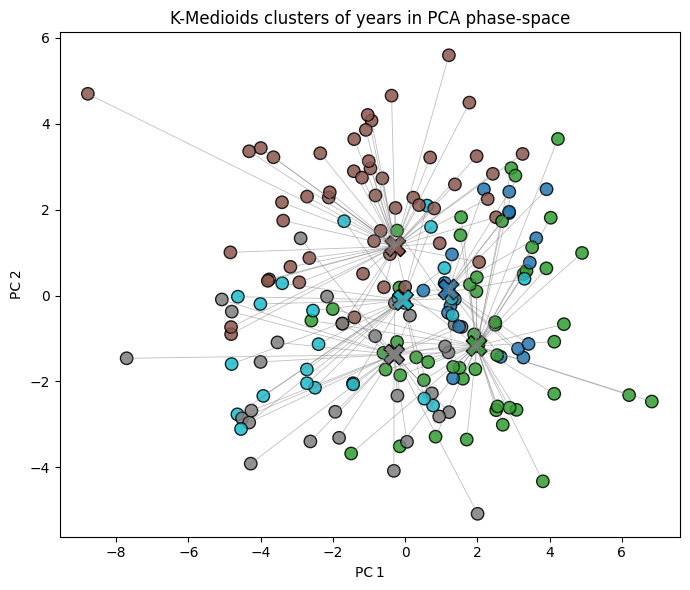

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

# years as coloured dots
pts = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmed.labels_,
    cmap="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k",
)

# lines to centroids (distance visualisation)
for i, (x, y) in enumerate(X_pca):
    cx, cy = centers_pca[kmed.labels_[i]]
    ax.plot([x, cx], [y, cy], lw=0.6, color="grey", alpha=0.5)

# centroids as large X‑markers
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    c=range(len(centers_pca)),
    cmap="tab10",
    s=220,
    edgecolor="k",
)

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("K-Medioids clusters of years in PCA phase‑space")
plt.tight_layout()
plt.show()

In [10]:
loadings = pd.DataFrame(
    pca.components_.T,  # shape (n_feats, n_components)
    index=yearly_stats.columns[:-1],  # drop 'cluster'
    columns=["PC1", "PC2"],
).round(3)

print("PCA loadings (coefficients):")
print(loadings)
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(3))

PCA loadings (coefficients):
                     PC1    PC2
NL_OFF_mean        0.292 -0.163
NL_OFF_var         0.234  0.098
NL_OFF_p95_day     0.303 -0.009
NL_OFF_p5_day      0.110 -0.174
NL_OFF_p95_week    0.314  0.053
NL_OFF_p5_week     0.024 -0.259
NL_ON_mean         0.321 -0.125
NL_ON_var          0.326  0.011
NL_ON_p95_day      0.323 -0.018
NL_ON_p5_day       0.114 -0.166
NL_ON_p95_week     0.320  0.053
NL_ON_p5_week      0.051 -0.259
NL_SOLAR_mean     -0.058  0.294
NL_SOLAR_var       0.065  0.318
NL_SOLAR_p95_day   0.048  0.291
NL_SOLAR_p5_day   -0.081 -0.211
NL_SOLAR_p95_week  0.033  0.369
NL_SOLAR_p5_week  -0.063 -0.065
NL_TEMP_mean       0.136  0.239
NL_TEMP_var       -0.253  0.113
NL_TEMP_p95_day   -0.017  0.321
NL_TEMP_p5_day     0.248  0.092
NL_TEMP_p95_week  -0.008  0.319
NL_TEMP_p5_week    0.243  0.098

Explained variance ratio: [0.307 0.195]


# 4. Analyze centroids

In [44]:
indices = kmed.medoid_indices_
centroid_years = yearly_mean_anom_norm.iloc[indices].copy()
centroid_years["count"] = (
    yearly_stats["cluster_med"].value_counts(sort=False).sort_index().values
)
centroid_years["cluster_id"] = range(5)
centroid_years = centroid_years.reset_index().set_index("cluster_id")

fname_centroids = os.path.join(BASE_OUTPUT, "centroids/centroid_years.csv")
centroid_years.to_csv(fname_centroids)
centroid_years

,model,Date,NL_OFF,NL_ON,NL_SOLAR,NL_TEMP,CDD,HDD,count
cluster_id,,,,,,,,,
0,ec_earth3,2023,-2.122654,0.146690,-0.065266,10.987888,-58.584744,-30.834492,20
1,mpi_esm1_2_hr,2027,4.980678,6.482114,-2.428863,-2.992672,-100.000000,4.974705,51
2,cmcc_cm2_sr5,2035,-2.747994,-2.357555,2.741770,6.329687,-100.000000,-1.183396,53
3,ec_earth3,2026,-0.384689,-0.076137,-4.818943,6.931053,-100.000000,-21.003107,31
4,mri_esm2_0,2027,-2.201913,-0.712021,4.361214,-0.512586,-100.000000,6.015987,25


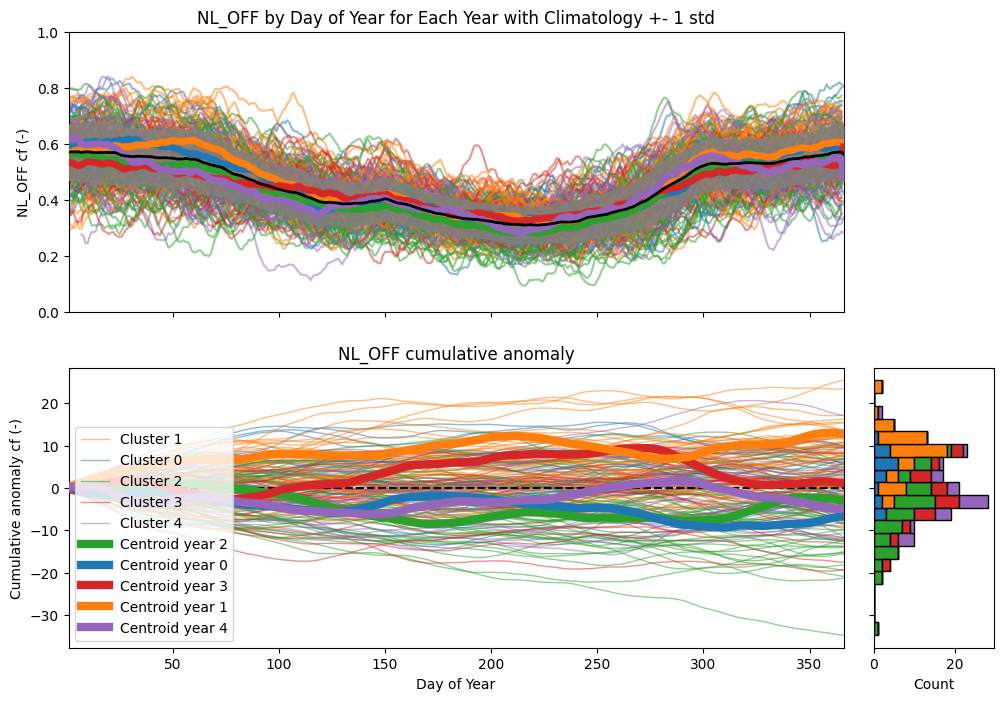

In [12]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_OFF")

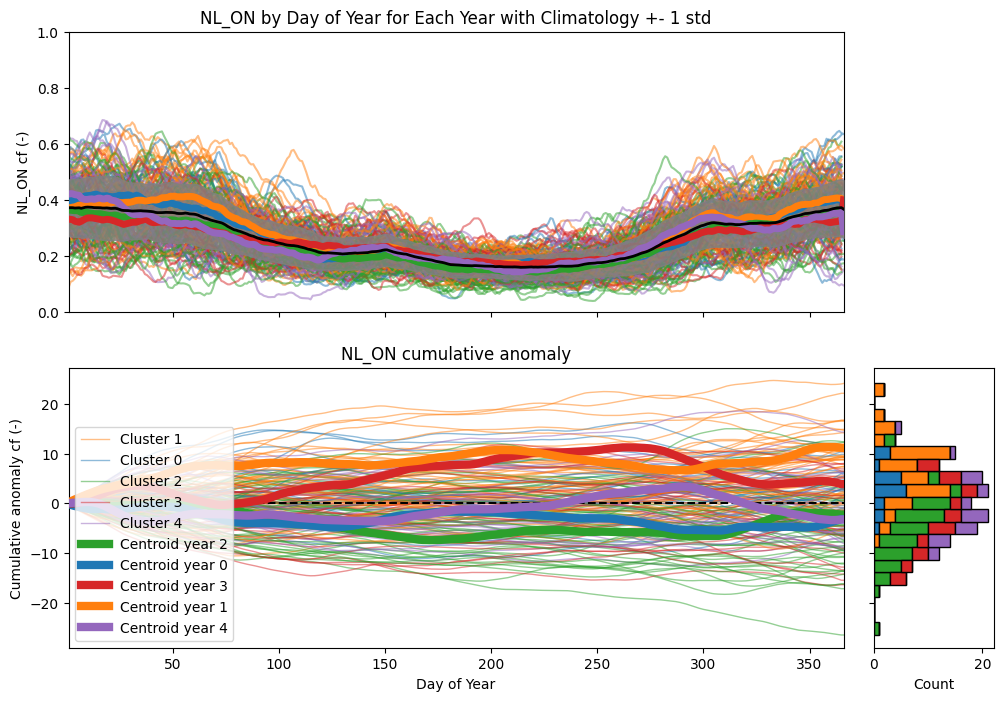

In [13]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_ON")

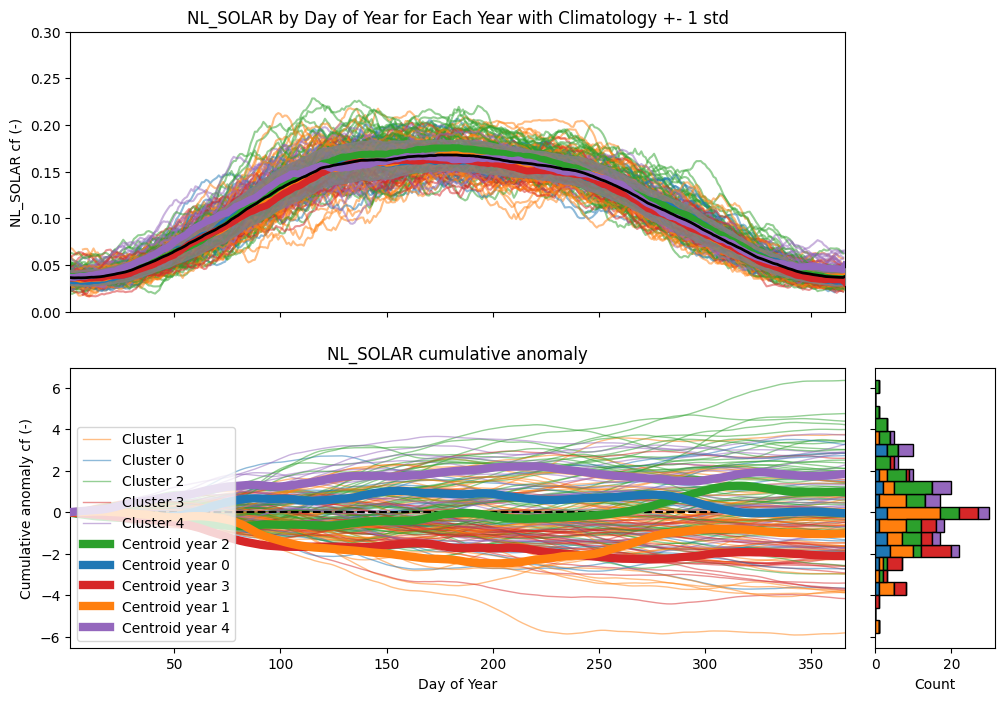

In [14]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_SOLAR")

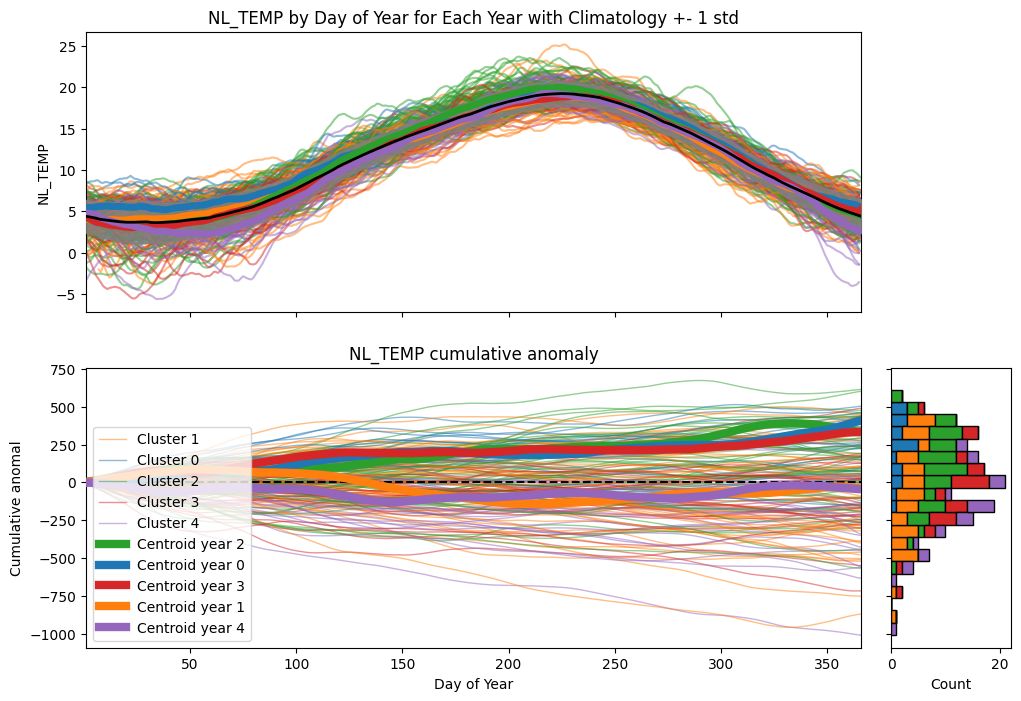

In [15]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_TEMP")